# Tokamak Hackathon — предсказание срыва плазмы

Ноутбук сравнивает три варианта признаков на **одинаковом разбиении по разрядам**:

1. **Raw** — измеряемые каналы и время, без ручной инженерии признаков.
2. **Physics** — исходные каналы плюс интерпретируемые физические прокси.
3. **Dynamics** — физические признаки плюс лаги, разности и скользящие статистики, использующие только текущие и прошлые измерения.

Цель — предсказать, произойдёт ли термическое гашение в ближайшие `LEAD_TIME_S` секунд. Используется `t_tq_s` из `shots.csv`; `t_trigger_s` не подменяет время термического гашения.

**Принципиальные ограничения:** `shot_id` нужен для группировки, но не является признаком; поля из `shots.csv` не передаются модели; после `t_tq_s` строки зривного разряда удаляются; в лаговых признаках запрещено заполнять пропуски будущими значениями (`bfill`). Метрики предупреждения считаются по разрядам, а не только по строкам.

Сначала запусти ячейки сверху вниз. Файлы `measured.csv` и `shots.csv` должны лежать рядом с ноутбуком.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

# XGBoost обычно хорошо подходит для табличных данных.
# Если он не установлен, используем sklearn HistGradientBoostingClassifier.
try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
    MODEL_BACKEND = "XGBoost"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGBOOST = False
    MODEL_BACKEND = "HistGradientBoostingClassifier"

RANDOM_STATE = 42
MEASURED_FILE = Path("measured.csv")
SHOTS_FILE = Path("shots.csv")

# Горизонт целевой метки (секунды до t_Q).
# Для сравнения вариантов используем один и тот же горизонт.
LEAD_TIME_S = 0.30

# Допустимая доля безопасных разрядов, на которых появится ложная тревога.
FALSE_ALARM_BUDGET = 0.05
VALID_SIZE = 0.25
N_JOBS = 4

print("Backend:", MODEL_BACKEND)
print("Lead time:", LEAD_TIME_S, "s")
print("False-alarm budget:", f"{FALSE_ALARM_BUDGET:.1%}")

Backend: XGBoost
Lead time: 0.3 s
False-alarm budget: 5.0%


In [2]:
# 1. Загрузка и первичная проверка данных
if not MEASURED_FILE.exists():
    raise FileNotFoundError(f"Не найден файл: {MEASURED_FILE.resolve()}")
if not SHOTS_FILE.exists():
    raise FileNotFoundError(f"Не найден файл: {SHOTS_FILE.resolve()}")

measured = pd.read_csv(MEASURED_FILE)
shots = pd.read_csv(SHOTS_FILE)

# Иногда CSV после экспорта содержит лишний индексный столбец.
measured = measured.loc[:, ~measured.columns.astype(str).str.startswith("Unnamed:")].copy()
shots = shots.loc[:, ~shots.columns.astype(str).str.startswith("Unnamed:")].copy()

required_measured = {"shot_id", "t", "mag_ip_MA", "mag_bt_T"}
required_shots = {"shot_id", "disrupted", "t_tq_s"}
missing_m = required_measured - set(measured.columns)
missing_s = required_shots - set(shots.columns)
if missing_m:
    raise ValueError(f"В measured.csv не хватает обязательных колонок: {sorted(missing_m)}")
if missing_s:
    raise ValueError(
        f"В shots.csv не хватает колонок: {sorted(missing_s)}. Нужен именно t_tq_s — время термического гашения."
    )

# Типы shot_id должны совпадать в обоих файлах.
measured["shot_id"] = pd.to_numeric(measured["shot_id"], errors="raise").astype("int64")
shots["shot_id"] = pd.to_numeric(shots["shot_id"], errors="raise").astype("int64")
measured["t"] = pd.to_numeric(measured["t"], errors="coerce")
shots["t_tq_s"] = pd.to_numeric(shots["t_tq_s"], errors="coerce")

if shots["shot_id"].duplicated().any():
    raise ValueError("В shots.csv есть повторяющиеся shot_id: ожидается одна строка на разряд.")

# Все колонки measured, кроме shot_id, должны быть числовыми измерениями.
# Пустые ячейки остаются NaN: это отказ/пропуск канала, а не нулевое измерение.
measured_channels = [c for c in measured.columns if c != "shot_id"]
for col in measured_channels:
    measured[col] = pd.to_numeric(measured[col], errors="coerce")

print(f"measured: {measured.shape[0]:,} строк × {measured.shape[1]} колонок")
print(f"shots:    {shots.shape[0]:,} разрядов × {shots.shape[1]} колонок")
print("Измеряемых признаков (без shot_id):", len(measured_channels))
print("Временной шаг, медиана по разрядам:")
print(measured.sort_values(["shot_id", "t"]).groupby("shot_id")["t"].diff().median())

display(shots.head())
display(measured.head(3))

measured: 272,176 строк × 102 колонок
shots:    100 разрядов × 9 колонок
Измеряемых признаков (без shot_id): 101
Временной шаг, медиана по разрядам:
0.004999999999999893


,shot_id,scenario,disrupted,t_trigger_s,t_tq_s,spontaneous,wall_contact,n_steps,t_end_s
0,0,density+heat_loss,False,NaN,NaN,False,False,2990,14.950
1,1,low_q,False,NaN,NaN,False,False,3196,15.980
2,2,low_q+density,True,11.685,11.775,False,False,2354,11.770
3,3,density,True,11.015,11.080,True,False,2215,11.075
4,4,none,False,NaN,NaN,False,False,2801,14.005


,shot_id,t,mag_ip_MA,mag_bt_T,mag_diamag_MJ,mag_vloop_V,mag_mirnov_01,mag_mirnov_02,mag_mirnov_03,mag_mirnov_04,...,nbi_beam_energy_keV,nbi_source_current_A,nbi_source_2_current_A,ich_antenna_voltage_kV,prog_ip_MA,prog_bt_T,prog_ne_1e20,prog_p_nbi_MW,prog_p_ech_MW,prog_p_ich_MW
0,0,0.005,0.004,3.3236,0.00000,0.008,-0.001500,0.000750,-0.000375,-0.001125,...,107.05,0.0,0.0,0.0,0.003813,3.32099,0.028626,0.0,0.0,0.0
1,0,0.010,0.008,3.3271,0.00225,-0.008,-0.002625,-0.001875,-0.001875,-0.000375,...,100.25,0.0,0.0,0.0,0.007626,3.32099,0.029339,0.0,0.0,0.0
2,0,0.015,0.012,3.3250,0.00000,0.012,-0.002625,0.001125,-0.001125,0.001500,...,101.15,0.0,0.0,0.0,0.011439,3.32099,0.030052,0.0,0.0,0.0


## 1A. Первичный EDA: пропуски, диапазоны и гистограммы каналов

Этот блок нужен для диагностики, а не для автоматического изменения данных. Для гистограмм берётся случайная выборка строк, чтобы не строить сотни графиков по всему огромному CSV. Число пропусков считается по полному `measured.csv`. Для деревьев не нужно автоматически стандартизировать или разбивать все числовые каналы на бины: сначала смотрим на данные, а затем решаем, нужны ли конкретные преобразования.

Для гистограмм использовано строк: 100,000 из 272,176
Каналы с наибольшим количеством пропусков:


,missing_pct,n_unique,sample_min,sample_p01,sample_median,sample_p99,sample_max,near_constant
ifr_chord_mid_in,0.113,1673,-0.270000,8.750000e-02,1.145000,2.512500,4.320000,False
dalpha_midplane,0.101,719,0.000000,2.125000e-03,0.078625,0.845750,2.913380,False
sxr_03,0.097,2931,-0.055500,0.000000e+00,6.549000,32.264000,86.987000,False
ece_04,0.086,618,0.046000,4.600000e-02,2.196500,5.324500,7.325500,False
neutron_collimated,0.084,11,0.000000,0.000000e+00,0.005000,0.025000,0.045000,False
sxr_02,0.083,2040,-0.055500,0.000000e+00,4.199500,21.441500,54.630500,False
dalpha_div_inner,0.076,1838,0.002125,6.375000e-03,0.233750,2.479880,7.006130,False
gas_valve_ne_cmd,0.074,40787,0.000000,0.000000e+00,0.013970,1.599580,1.977800,False
bolo_05,0.067,1238,-0.037500,-6.250000e-03,0.462500,2.931250,13.150000,False
coil_tf_voltage_V,0.065,105,1.787500,1.812500e+00,2.475000,3.037500,3.087500,False


Почти постоянные/постоянные каналы:


,missing_pct,n_unique,sample_min,sample_p01,sample_median,sample_p99,sample_max,near_constant


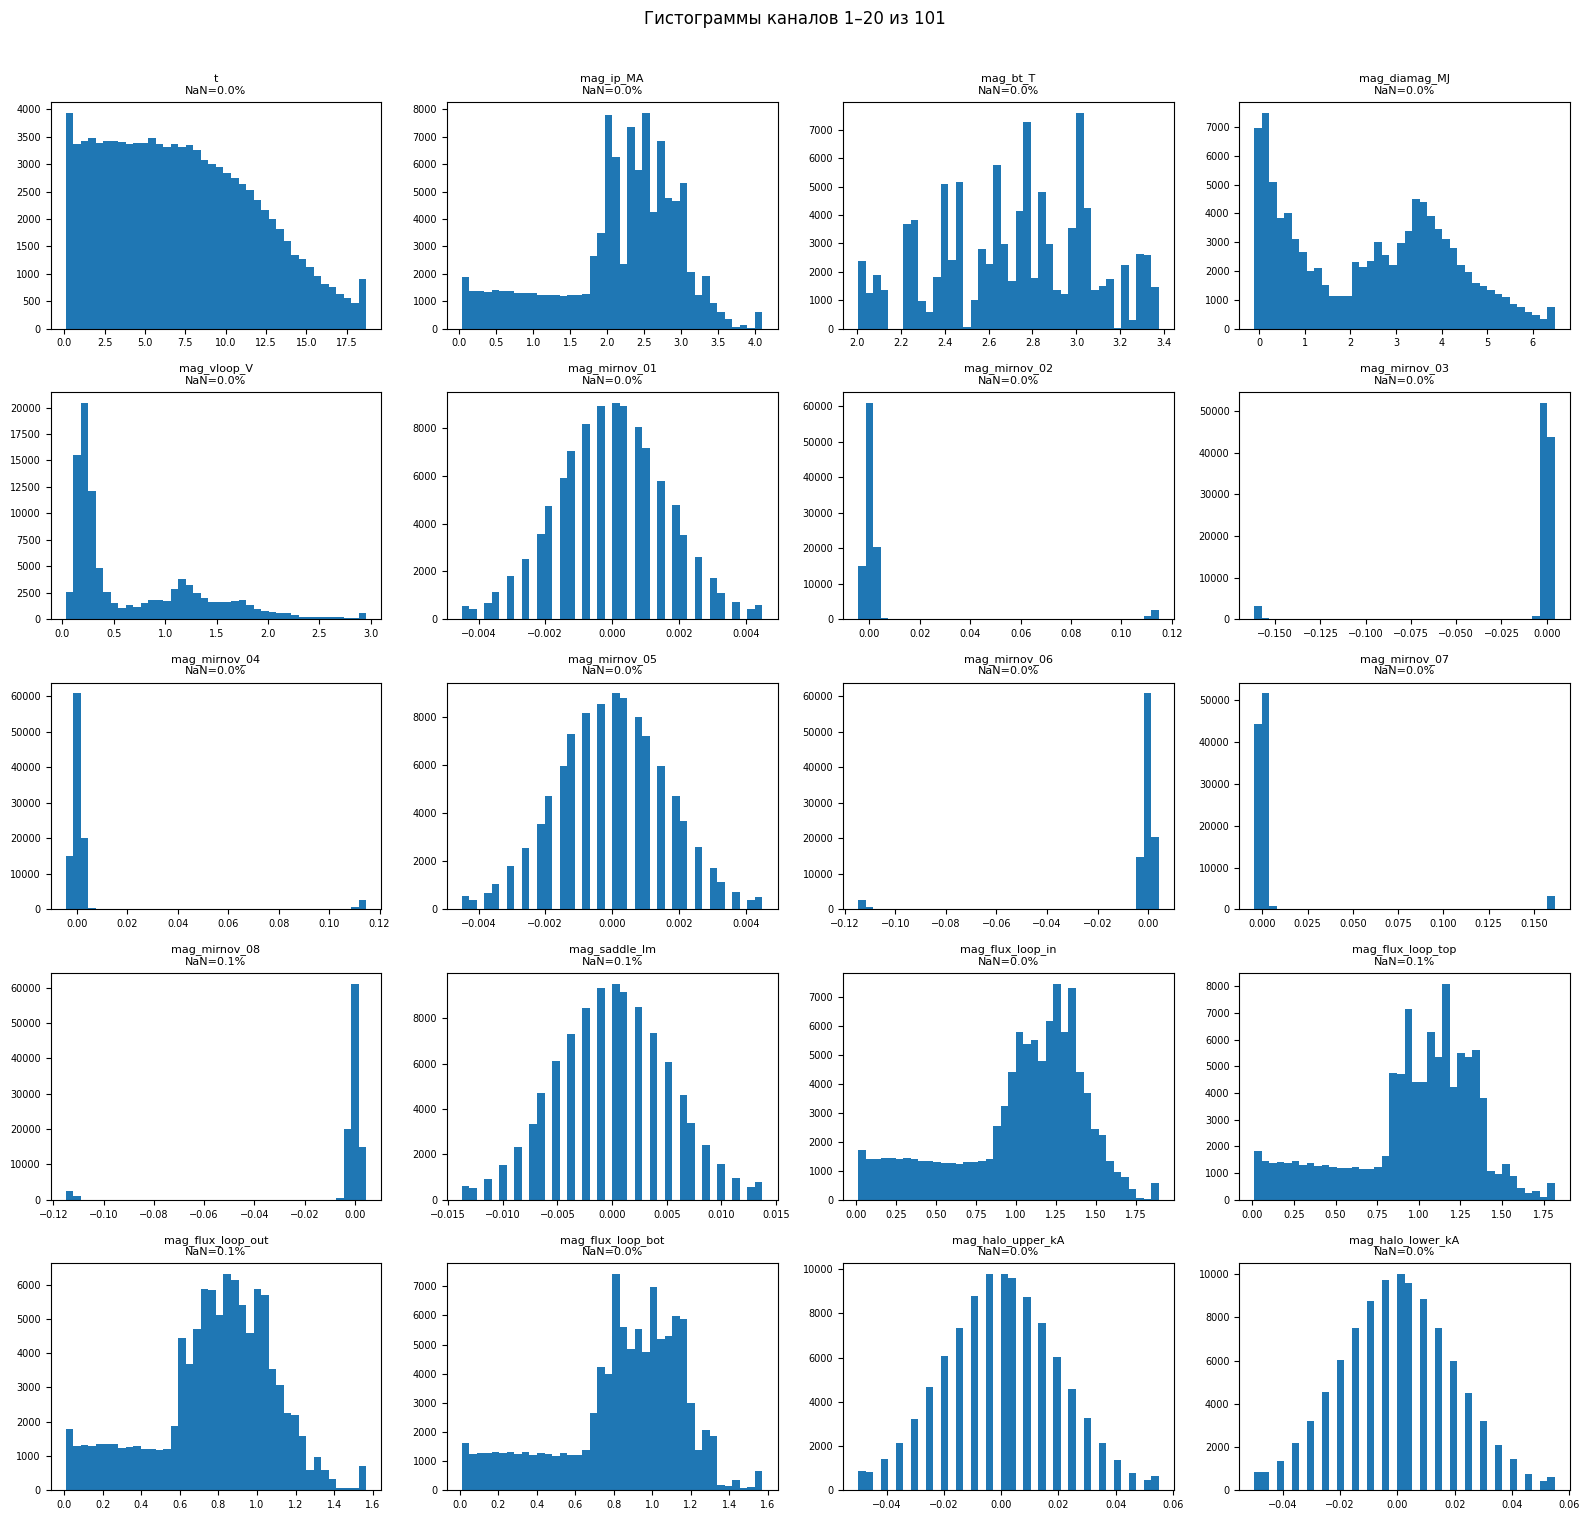

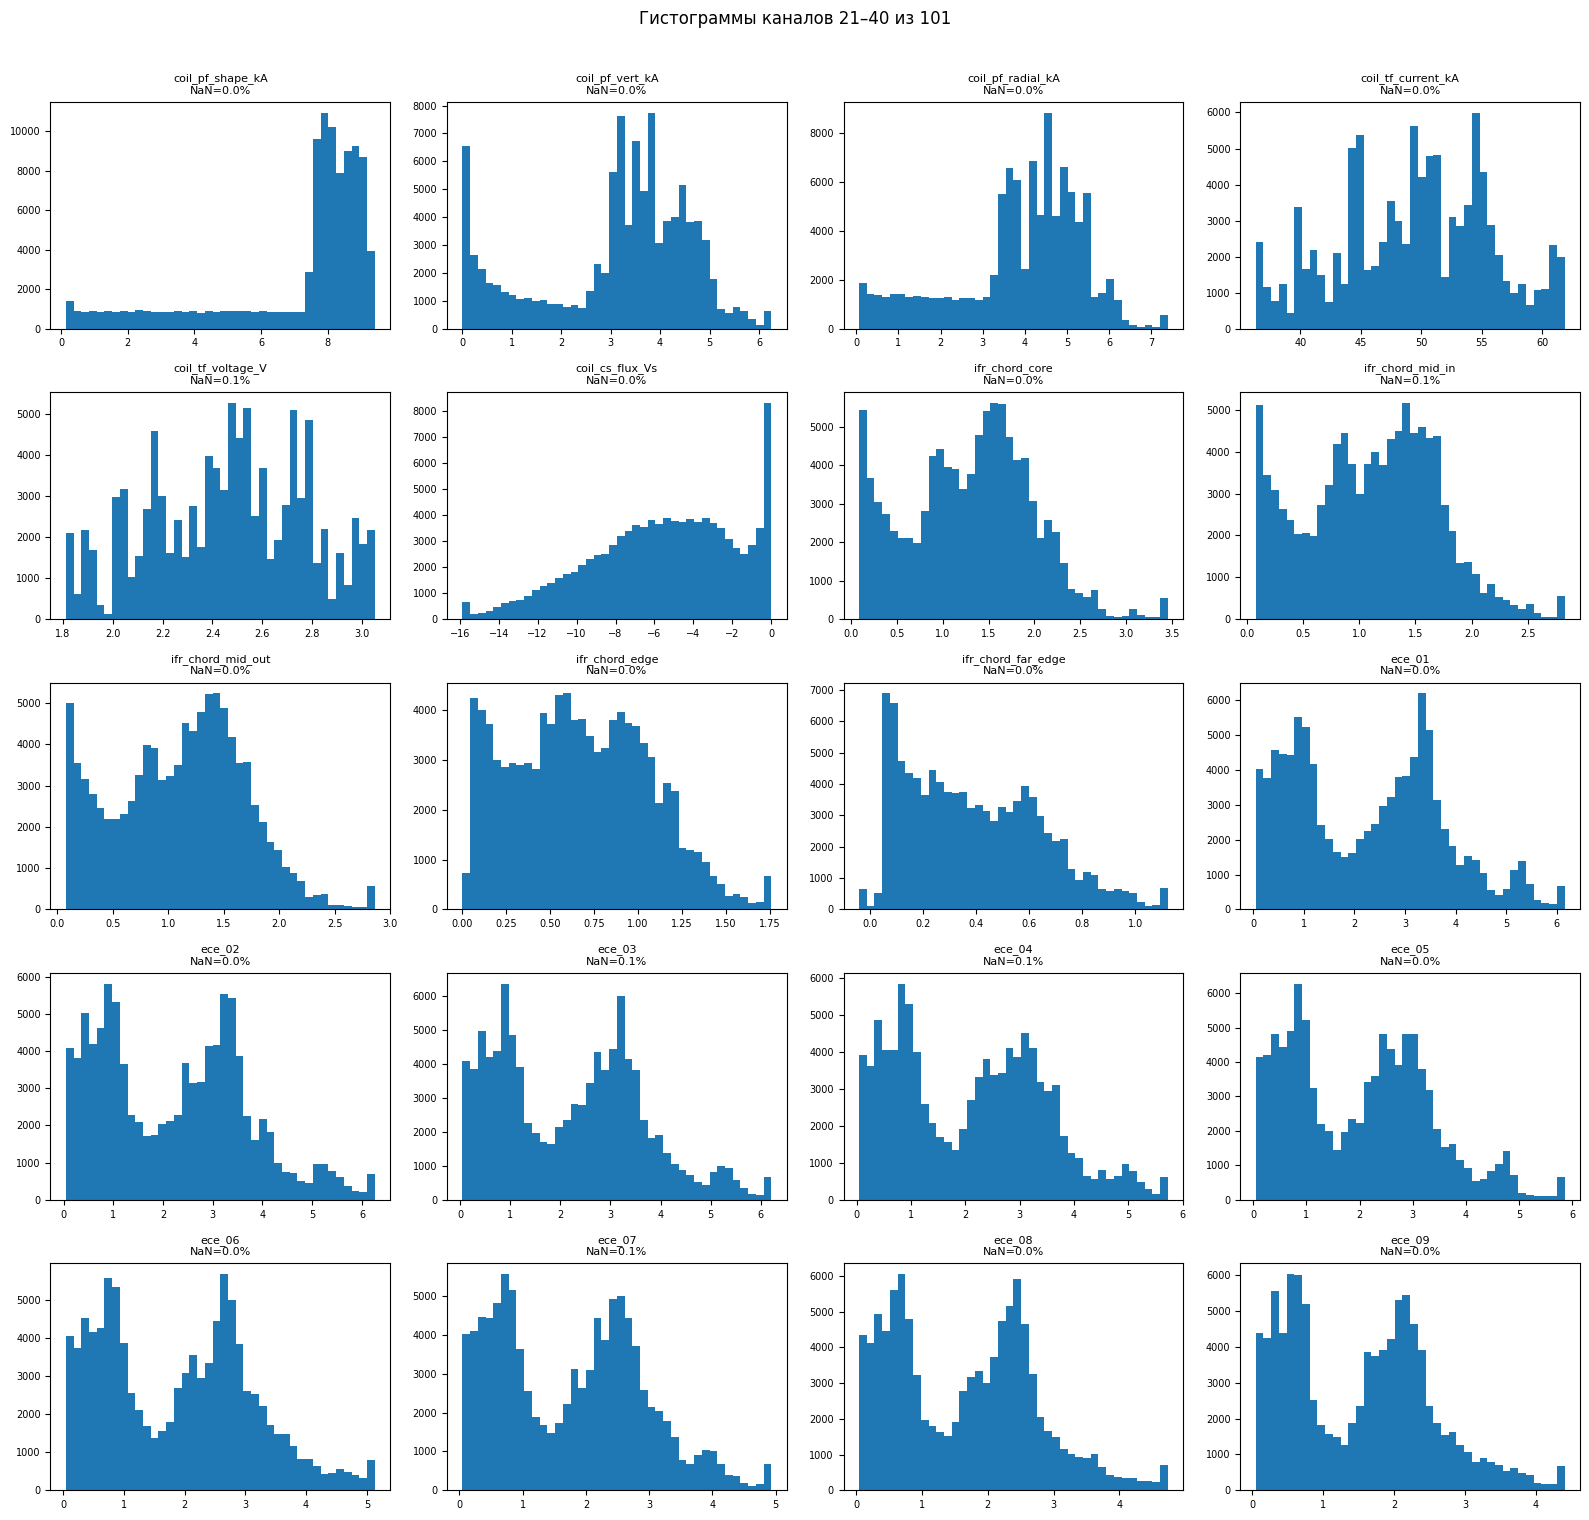

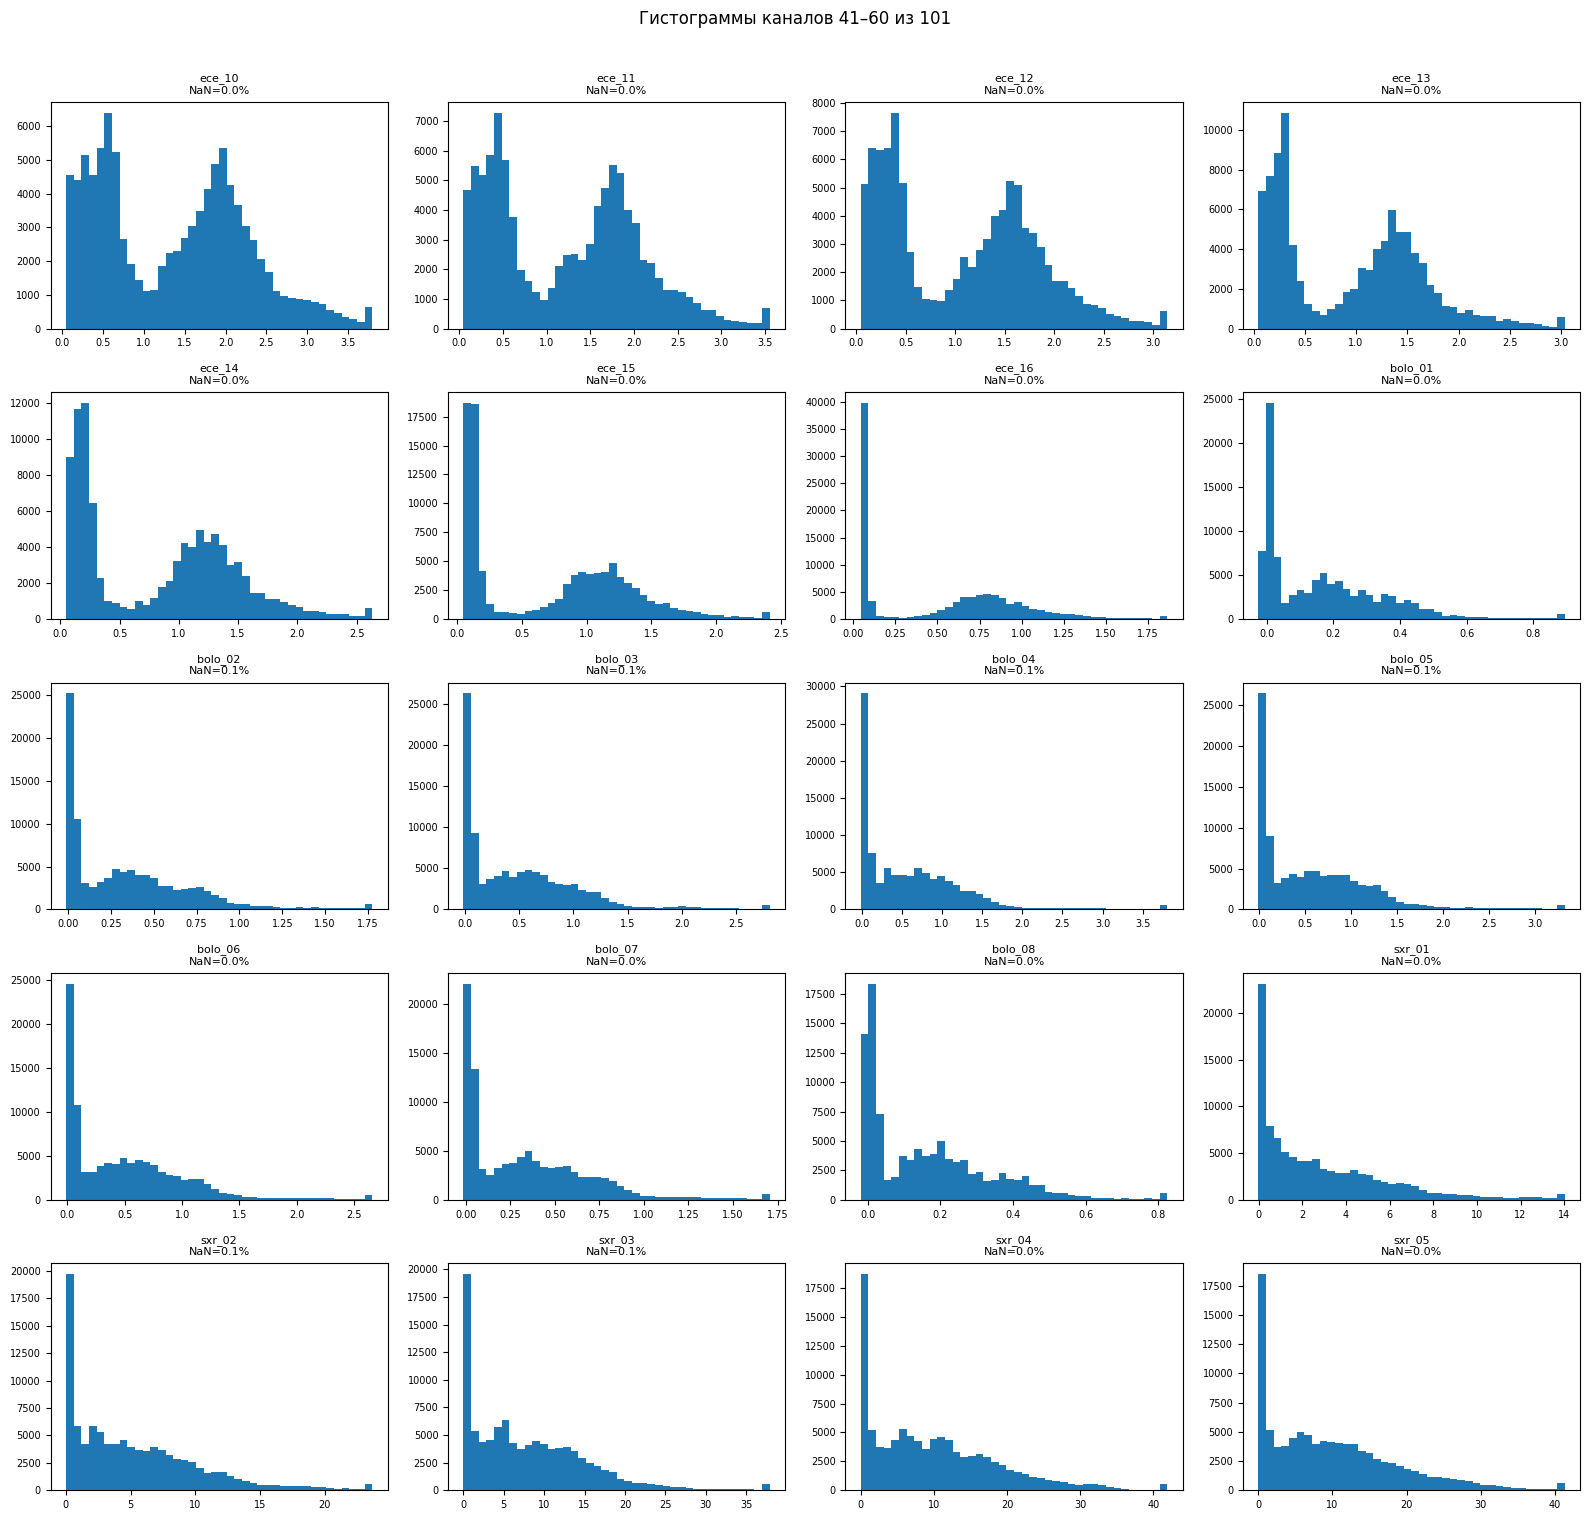

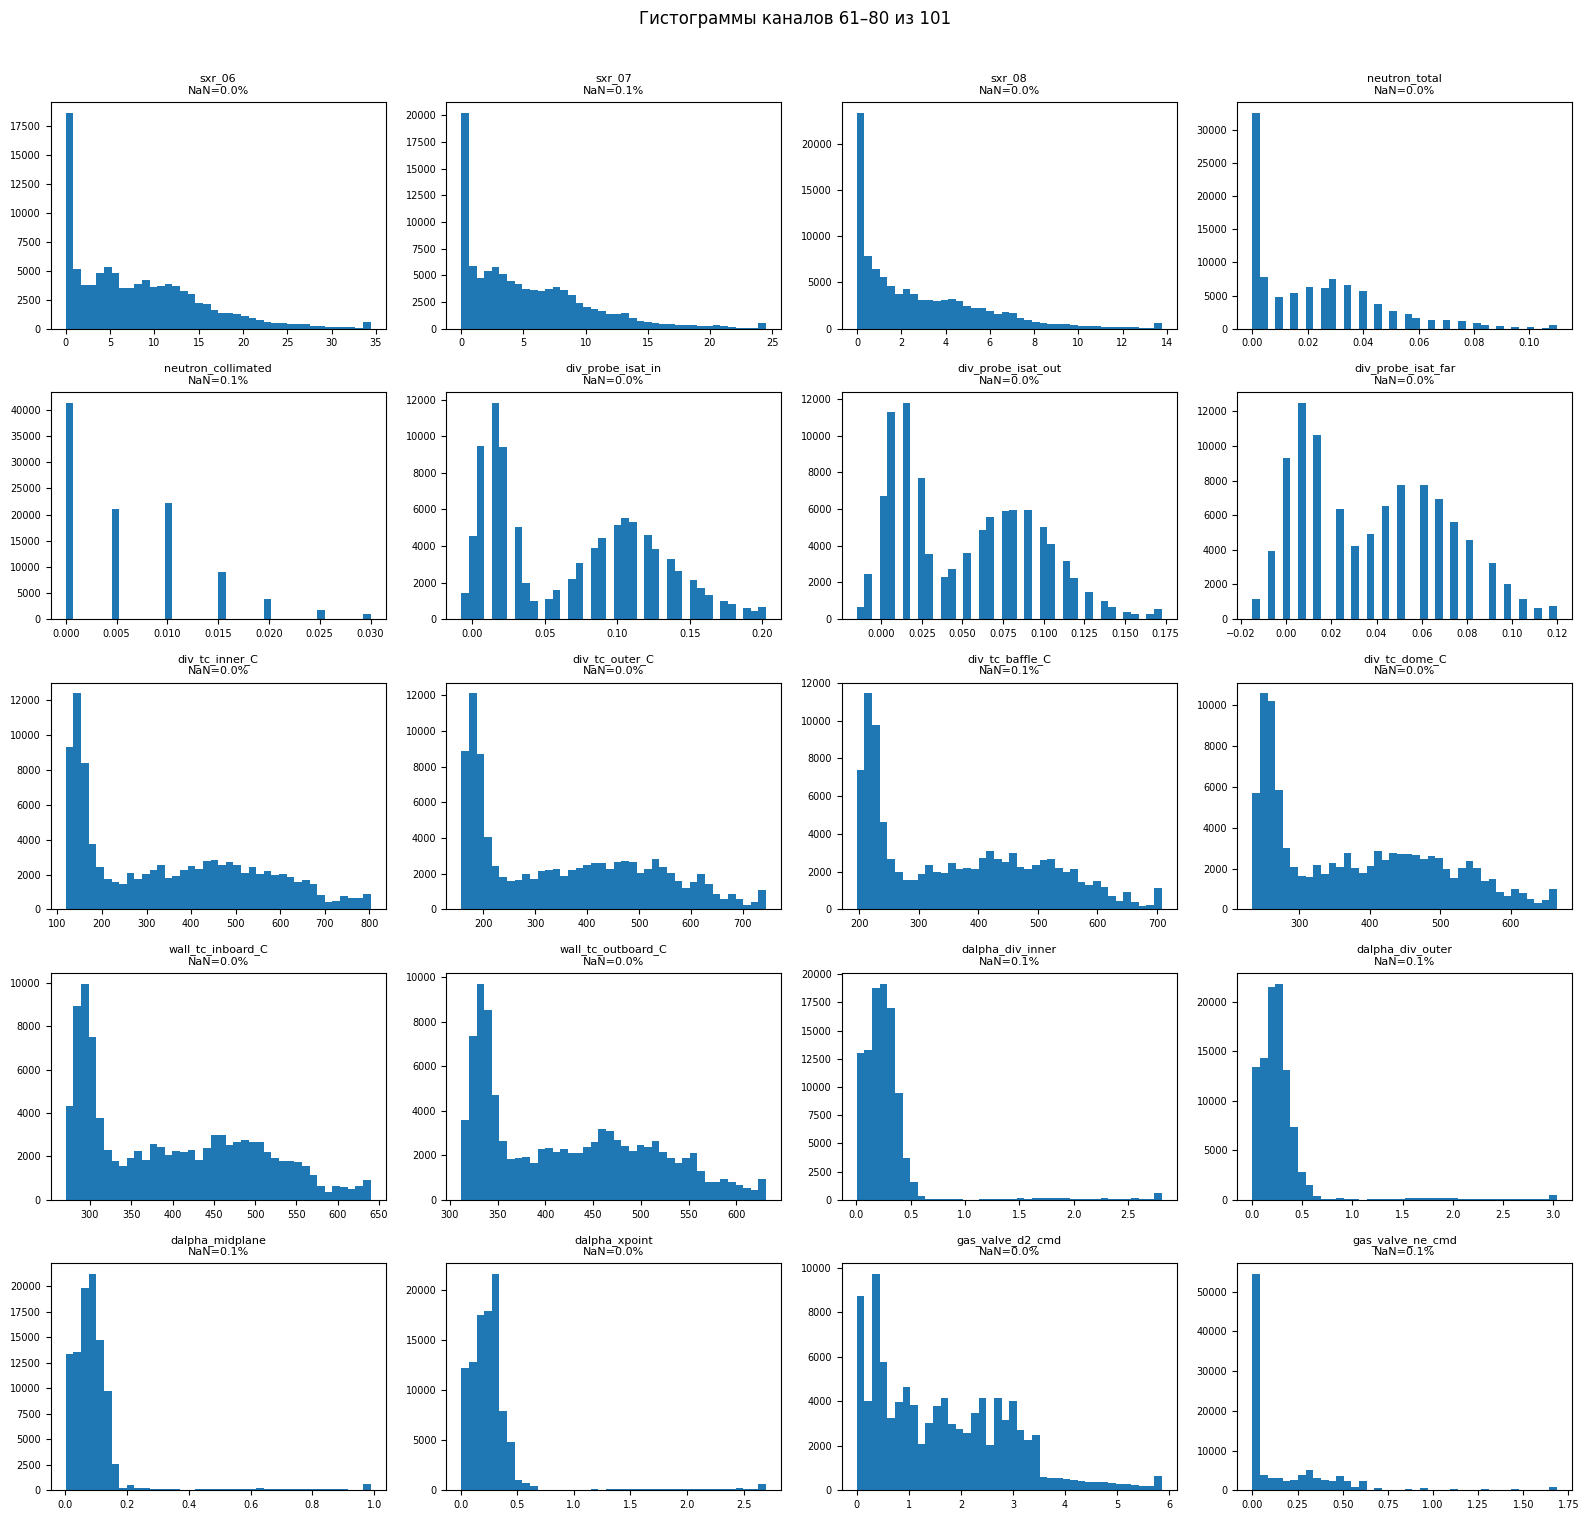

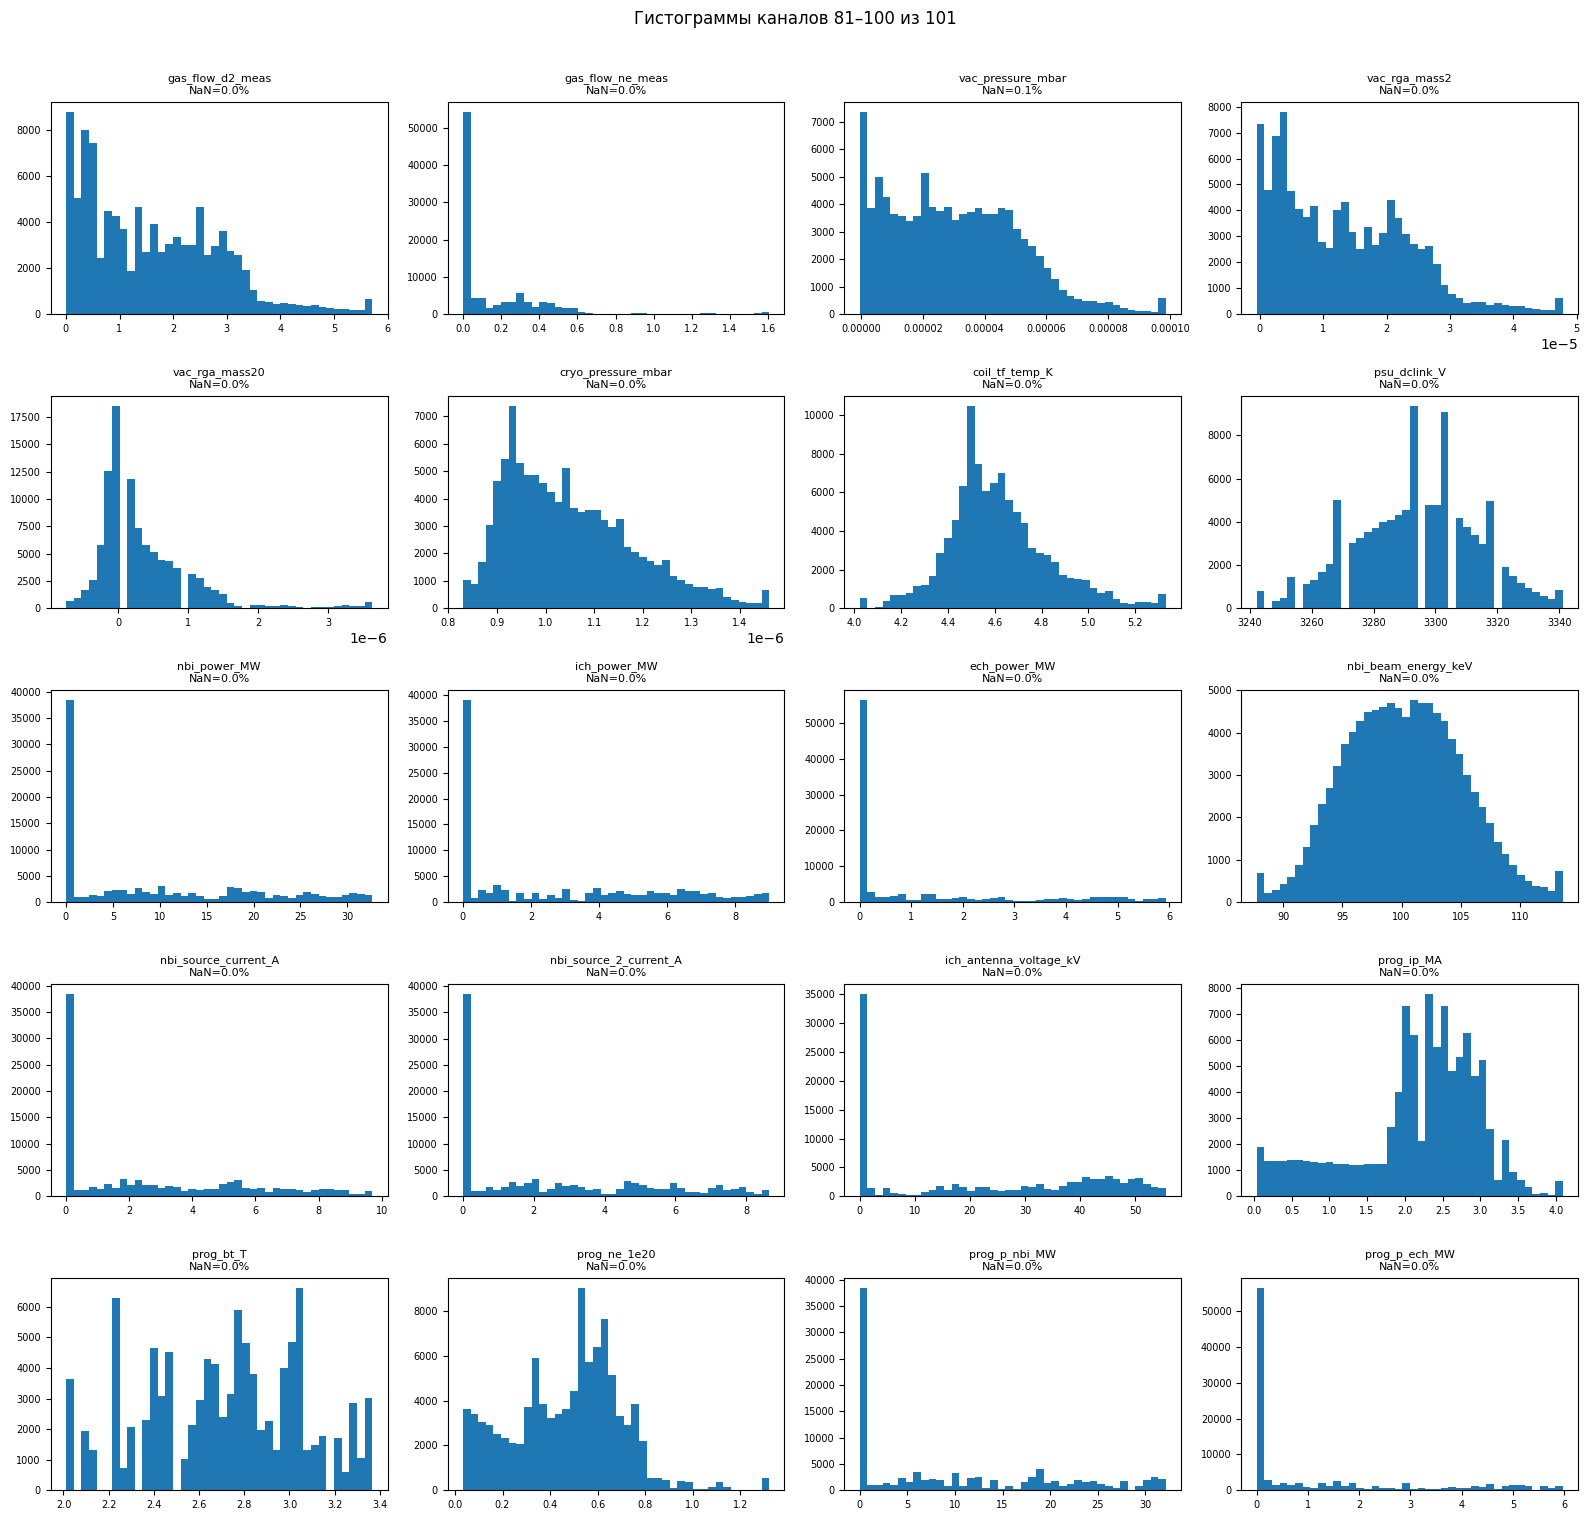

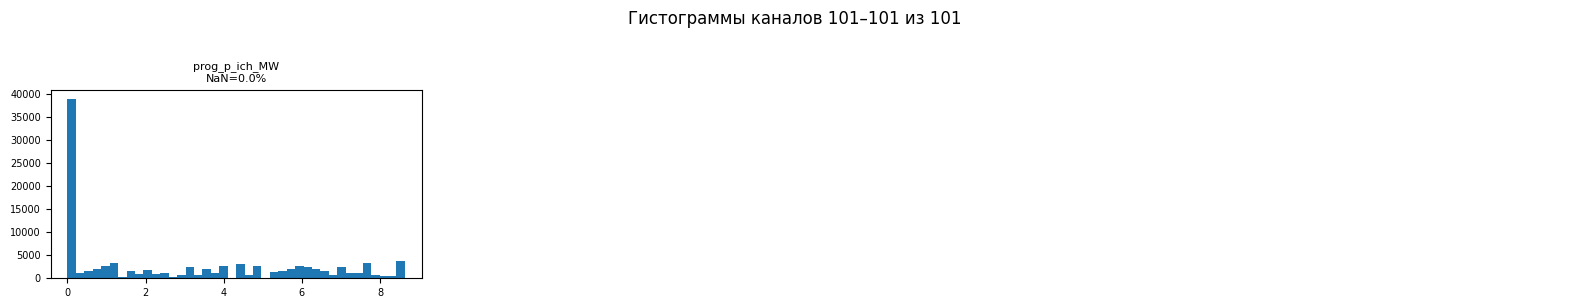

In [3]:
import math
import matplotlib.pyplot as plt

EDA_MAX_ROWS = 100_000
eda_numeric = measured.drop(columns=["shot_id"], errors="ignore").select_dtypes(include=[np.number])
if len(eda_numeric) > EDA_MAX_ROWS:
    rng = np.random.default_rng(RANDOM_STATE)
    chosen = np.sort(rng.choice(len(eda_numeric), size=EDA_MAX_ROWS, replace=False))
    eda_sample = eda_numeric.iloc[chosen].copy()
else:
    eda_sample = eda_numeric.copy()

# Полная доля пропусков/число уникальных значений + приближённые квантили по выборке.
eda_profile = pd.DataFrame({
    "missing_pct": (eda_numeric.isna().mean() * 100).round(3),
    "n_unique": eda_numeric.nunique(dropna=True),
    "sample_min": eda_sample.min(skipna=True),
    "sample_p01": eda_sample.quantile(0.01),
    "sample_median": eda_sample.median(skipna=True),
    "sample_p99": eda_sample.quantile(0.99),
    "sample_max": eda_sample.max(skipna=True),
})
eda_profile["near_constant"] = eda_profile["n_unique"] <= 2
print(f"Для гистограмм использовано строк: {len(eda_sample):,} из {len(eda_numeric):,}")
print("Каналы с наибольшим количеством пропусков:")
display(eda_profile.sort_values("missing_pct", ascending=False).head(25))
print("Почти постоянные/постоянные каналы:")
display(eda_profile.loc[eda_profile["near_constant"]].sort_values("n_unique"))

# Показываем гистограммы всех числовых каналов пачками, чтобы выход не был одной гигантской фигурой.
eda_columns = list(eda_numeric.columns)
BATCH_SIZE = 20
for start in range(0, len(eda_columns), BATCH_SIZE):
    batch = eda_columns[start:start + BATCH_SIZE]
    ncols = 4
    nrows = math.ceil(len(batch) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.0 * nrows))
    axes = np.asarray(axes).reshape(-1)
    for ax, col in zip(axes, batch):
        values = eda_sample[col].replace([np.inf, -np.inf], np.nan).dropna()
        if values.empty:
            ax.set_title(f"{col}\nнет чисел", fontsize=8)
            ax.axis("off")
            continue
        # Обрезка только на картинке, чтобы хвост не сжимал основную массу.
        lo, hi = values.quantile([0.005, 0.995])
        shown = values.clip(lower=lo, upper=hi) if lo < hi else values
        ax.hist(shown, bins=40)
        ax.set_title(f"{col}\nNaN={eda_profile.loc[col, 'missing_pct']:.1f}%", fontsize=8)
        ax.tick_params(axis="both", labelsize=7)
    for ax in axes[len(batch):]:
        ax.axis("off")
    fig.suptitle(f"Гистограммы каналов {start + 1}–{start + len(batch)} из {len(eda_columns)}", y=1.01)
    fig.tight_layout()
    plt.show()


## 2. Подготовка таргета

Для зривного разряда метка равна 1, если `0 < t_tq_s - t <= LEAD_TIME_S`; раньше этого окна и для безопасных разрядов метка равна 0. Строки при `t >= t_tq_s` исключаются, поскольку это уже не прогноз до гашения.

Разряды со срывом, помеченным как `spontaneous` или `wall_contact`, а также зривные разряды без `t_tq_s`, исключаются из обучения и оценки: методичка относит их к `Excluded`. Безопасные разряды сохраняются.

In [4]:
def as_bool(series: pd.Series) -> pd.Series:
    """Надёжно переводит CSV-значения true/false в bool."""
    return series.astype(str).str.strip().str.lower().isin({"true", "1", "yes", "y", "t"})

shots = shots.copy()
shots["disrupted_bool"] = as_bool(shots["disrupted"])
if "spontaneous" in shots:
    shots["spontaneous_bool"] = as_bool(shots["spontaneous"])
else:
    shots["spontaneous_bool"] = False
if "wall_contact" in shots:
    shots["wall_contact_bool"] = as_bool(shots["wall_contact"])
else:
    shots["wall_contact_bool"] = False

bad_disruption = (
    shots["disrupted_bool"]
    & (
        shots["spontaneous_bool"]
        | shots["wall_contact_bool"]
        | shots["t_tq_s"].isna()
    )
)
excluded_shot_ids = set(shots.loc[bad_disruption, "shot_id"])
shots_eligible = shots.loc[~bad_disruption].copy()

# Объединяем только служебные поля для построения метки/оценки.
# Эти поля не войдут в матрицу признаков.
meta_cols = [
    "shot_id", "disrupted_bool", "t_tq_s",
    "spontaneous_bool", "wall_contact_bool",
]
df = measured.merge(
    shots_eligible[meta_cols],
    on="shot_id",
    how="inner",
    validate="many_to_one",
)
df = df.sort_values(["shot_id", "t"]).reset_index(drop=True)

# После t_Q нет прогноза: убираем строки гашения и возможные строки после него.
post_quench = df["disrupted_bool"] & (df["t"] >= df["t_tq_s"])
df = df.loc[~post_quench].copy().reset_index(drop=True)

time_to_tq = df["t_tq_s"] - df["t"]
df["target_y"] = (
    df["disrupted_bool"]
    & (time_to_tq > 0)
    & (time_to_tq <= LEAD_TIME_S)
).astype("int8")

# Проверка качества метки и числа разрядов.
y = df["target_y"].astype("int8")
shot_info = shots_eligible[meta_cols].drop_duplicates("shot_id").copy()
print(f"Исключено непригодных зривных разрядов: {len(excluded_shot_ids)}")
print(f"Оставлено разрядов: {shot_info['shot_id'].nunique()}")
print(f"Строк после удаления данных t >= t_Q: {len(df):,}")
print(f"Положительных строк: {int(y.sum()):,} ({y.mean():.4%})")
print("Исходы разрядов:")
display(shot_info["disrupted_bool"].value_counts().rename(index={False: "без срыва", True: "допустимый срыв"}).to_frame("shots"))

if y.sum() == 0:
    raise ValueError(
        "Таргет не содержит положительных строк. Проверь t_tq_s и LEAD_TIME_S; не заменяй t_tq_s на t_trigger_s автоматически."
    )
if shot_info["disrupted_bool"].nunique() < 2:
    raise ValueError("Нужны как безопасные, так и зривные разряды для сравнения модели.")

Исключено непригодных зривных разрядов: 7
Оставлено разрядов: 93
Строк после удаления данных t >= t_Q: 260,953
Положительных строк: 2,078 (0.7963%)
Исходы разрядов:


,shots
disrupted_bool,
без срыва,58
допустимый срыв,35


## 3. Три набора признаков

- **Raw:** все исходные числовые колонки `measured.csv`, включая `t` и доступные `prog_*`; `shot_id` исключается из X. Явной импутации, масштабирования и биннинга нет.
- **Physics:** Raw плюс агрегаты ECE/болометрии/SXR/Mirnov/D-alpha/интерферометра, отношения между измерительными каналами и ошибки слежения. В этой версии намеренно отсутствуют `q95`-прокси, отношение `Ip/Bt` и отношение нагрева к энергии, чтобы не кодировать формулы из шпаргалки. Прокси остаются диагностическими признаками, а не восстановленными истинными состояниями.
- **Dynamics:** Physics плюс лаги, разности, скорости изменения тока/мощности, скользящие средние/разбросы/максимумы и индикатор активности D-alpha. Окна используют только текущие и прошлые строки внутри одного разряда; `bfill` нигде не применяется.

Деревья обычно сами справляются с асимметричными распределениями, масштабированием и поиском порогов. Поэтому гистограммы нужны прежде всего для диагностики пропусков, выбросов и странных каналов, а не для ручного биннинга всех признаков.

In [5]:
def _row_agg(frame: pd.DataFrame, columns, how="mean") -> pd.Series:
    cols = [c for c in columns if c in frame.columns]
    if not cols:
        return pd.Series(np.nan, index=frame.index, dtype=float)
    values = frame[cols]
    if how == "mean":
        return values.mean(axis=1)
    if how == "max":
        return values.max(axis=1)
    if how == "min":
        return values.min(axis=1)
    if how == "std":
        return values.std(axis=1)
    if how == "rms":
        return np.sqrt((values ** 2).mean(axis=1))
    if how == "abs_sum":
        return values.abs().sum(axis=1, min_count=1)
    raise ValueError(f"Неизвестная агрегация: {how}")


def make_physics_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Исходные измерения + физически мотивированные диагностические прокси.

    Важные оговорки:
    - это не восстановленные истинные состояния симулятора;
    - болометрические и интерферометрические агрегаты имеют смысл как прокси,
      пока не подтверждены точная калибровка и единицы измерения;
    - используются только каналы measured.csv, доступные модели на текущем шаге.
    """
    out = raw.copy()
    eps_ip = 0.03  # защита отношений в начале разряда при Ip около нуля
    eps = 1e-6

    # Измеренная суммарная мощность нагрева.
    heating_cols = [c for c in ["nbi_power_MW", "ich_power_MW", "ech_power_MW"] if c in out.columns]
    if heating_cols:
        out["feat_input_power_MW"] = out[heating_cols].clip(lower=0).sum(axis=1, min_count=1)

    # Intentionally no q95 or Ip/Bt-derived proxy: the cheat-sheet formulas are not used.

    # Интерферометрические хорды: агрегаты и относительный контраст профиля.
    chord_cols = [c for c in out.columns if c.startswith("ifr_chord_")]
    if chord_cols:
        out["feat_chord_mean"] = _row_agg(out, chord_cols, "mean")
        out["feat_chord_spread"] = _row_agg(out, chord_cols, "max") - _row_agg(out, chord_cols, "min")
        if "mag_ip_MA" in out.columns:
            out["feat_chord_per_current_proxy"] = out["feat_chord_mean"].abs() / (out["mag_ip_MA"].abs() + eps_ip)
        if {"ifr_chord_core", "ifr_chord_edge", "ifr_chord_far_edge"}.issubset(out.columns):
            edge_proxy = (out["ifr_chord_edge"].abs() + out["ifr_chord_far_edge"].abs()) / 2
            out["feat_ifr_edge_core_ratio_proxy"] = edge_proxy / (out["ifr_chord_core"].abs() + 0.01)

    # Магнитная активность по Mirnov-датчикам.
    mirnov_cols = [c for c in out.columns if c.startswith("mag_mirnov_")]
    if mirnov_cols:
        out["feat_mirnov_rms"] = _row_agg(out, mirnov_cols, "rms")

    # D-alpha: сигнал активности на краю и отношение пика к общей базе.
    dalpha_cols = [c for c in out.columns if c.startswith("dalpha_")]
    if dalpha_cols:
        out["feat_dalpha_mean_abs"] = out[dalpha_cols].abs().mean(axis=1)
        out["feat_dalpha_max_abs"] = out[dalpha_cols].abs().max(axis=1)
        out["feat_dalpha_peak_ratio_proxy"] = out["feat_dalpha_max_abs"] / (out["feat_dalpha_mean_abs"] + 1e-4)

    # ECE агрегаты и контраст двух половин каналов. Называем их половинами,
    # а не ядром/краем: точное пространственное соответствие индексов надо подтвердить.
    ece_cols = sorted([c for c in out.columns if c.startswith("ece_")])
    if ece_cols:
        out["feat_ece_mean"] = _row_agg(out, ece_cols, "mean")
        out["feat_ece_spread"] = _row_agg(out, ece_cols, "max") - _row_agg(out, ece_cols, "min")
        if len(ece_cols) >= 4:
            mid = len(ece_cols) // 2
            first_half_mean = out[ece_cols[:mid]].mean(axis=1)
            second_half_mean = out[ece_cols[mid:]].mean(axis=1)
            out["feat_ece_half_contrast"] = second_half_mean - first_half_mean

    # Болометрия: абсолютная активность и её распределение между каналами.
    # Это диагностические единицы; не называем их P_rad в MW.
    bolo_cols = [c for c in out.columns if c.startswith("bolo_")]
    if bolo_cols:
        abs_bolo = out[bolo_cols].abs()
        out["feat_bolo_abs_sum"] = abs_bolo.sum(axis=1, min_count=1)
        out["feat_bolo_max_abs"] = abs_bolo.max(axis=1)
        out["feat_bolo_concentration_proxy"] = out["feat_bolo_max_abs"] / (out["feat_bolo_abs_sum"] + 1e-6)
        if "feat_input_power_MW" in out.columns:
            out["feat_bolo_to_heating_proxy"] = out["feat_bolo_abs_sum"] / out["feat_input_power_MW"].abs().clip(lower=0.5)

    # Soft X-ray: параллельный диагностический агрегат.
    sxr_cols = [c for c in out.columns if c.startswith("sxr_")]
    if sxr_cols:
        abs_sxr = out[sxr_cols].abs()
        out["feat_sxr_abs_sum"] = abs_sxr.sum(axis=1, min_count=1)
        out["feat_sxr_max_abs"] = abs_sxr.max(axis=1)

    # Энергетическое соотношение и напряжение обхода — только приближённые прокси.
    # Intentionally omit the heating/energy ratio to avoid encoding the cheat-sheet energy-balance relation.
    if {"mag_vloop_V", "mag_ip_MA"}.issubset(out.columns):
        out["feat_vloop_per_current_proxy"] = out["mag_vloop_V"].abs() / (out["mag_ip_MA"].abs() + eps_ip)
    if "mag_saddle_lm" in out.columns:
        out["feat_locked_mode_abs"] = out["mag_saddle_lm"].abs()
    if "neutron_total" in out.columns:
        out["feat_neutron_log1p"] = np.log1p(out["neutron_total"].clip(lower=0))
    # Не добавляем отдельный столбец на каждое отношение: оставляем три понятные ошибки слежения.
    if {"mag_ip_MA", "prog_ip_MA"}.issubset(out.columns):
        out["feat_ip_tracking_error"] = out["mag_ip_MA"] - out["prog_ip_MA"]
    if {"mag_bt_T", "prog_bt_T"}.issubset(out.columns):
        out["feat_bt_tracking_error"] = out["mag_bt_T"] - out["prog_bt_T"]
    prog_heating_cols = [c for c in ["prog_p_nbi_MW", "prog_p_ech_MW", "prog_p_ich_MW"] if c in out.columns]
    if prog_heating_cols and "feat_input_power_MW" in out.columns:
        out["feat_heating_tracking_error"] = out["feat_input_power_MW"] - out[prog_heating_cols].clip(lower=0).sum(axis=1, min_count=1)

    if {"gas_flow_ne_meas", "gas_flow_d2_meas"}.issubset(out.columns):
        out["feat_neon_to_d2_flow_proxy"] = out["gas_flow_ne_meas"].abs() / (out["gas_flow_d2_meas"].abs() + 1e-8)

    # Агрегаты полоидальных корректирующих катушек: общая активность и асимметрия.
    pf_cols = [c for c in ["coil_pf_shape_kA", "coil_pf_vert_kA", "coil_pf_radial_kA"] if c in out.columns]
    if pf_cols:
        out["feat_pf_coil_abs_sum"] = out[pf_cols].abs().sum(axis=1, min_count=1)
    if {"coil_pf_vert_kA", "coil_pf_radial_kA"}.issubset(out.columns):
        out["feat_pf_radial_minus_vert"] = out["coil_pf_radial_kA"] - out["coil_pf_vert_kA"]

    return out.replace([np.inf, -np.inf], np.nan)


def make_dynamic_features(raw: pd.DataFrame) -> pd.DataFrame:
    """Physics-признаки + лаги, тренды и скользящие статистики только по прошлому/текущему."""
    out = make_physics_features(raw)
    if "shot_id" not in out.columns:
        raise ValueError("Для динамических признаков нужен shot_id, чтобы не смешивать разряды.")
    out = out.sort_values(["shot_id", "t"]).copy()
    dyn = {}  # Собираем колонки отдельно и склеиваем один раз: быстрее на больших CSV.

    # Лаги для ключевых измерений/прокси. При dt=5 ms: 1/3/10/20 строк ~= 5/15/50/100 ms.
    lag_sources = [
        "mag_ip_MA", "prog_ip_MA", "mag_saddle_lm", "mag_diamag_MJ",
        "mag_vloop_V", "ifr_chord_core", "neutron_total", "feat_dalpha_max_abs",
        "feat_mirnov_rms", "feat_input_power_MW", "feat_bolo_abs_sum", "feat_sxr_abs_sum",
    ]
    for col in [c for c in lag_sources if c in out.columns]:
        grouped = out.groupby("shot_id", sort=False)[col]
        for lag in (1, 3, 10, 20):
            dyn[f"dyn__{col}__lag{lag}"] = grouped.shift(lag)

    # Разности и скорости изменения. Нормируем скорость на фактический временной интервал,
    # чтобы признаки оставались осмысленными и при Sample every > 1.
    delta_sources = [
        "mag_ip_MA", "prog_ip_MA", "mag_saddle_lm", "mag_diamag_MJ",
        "neutron_total", "feat_dalpha_max_abs", "feat_mirnov_rms",
        "feat_bolo_abs_sum", "feat_input_power_MW",
    ]
    grouped_t = out.groupby("shot_id", sort=False)["t"]
    for col in [c for c in delta_sources if c in out.columns]:
        grouped = out.groupby("shot_id", sort=False)[col]
        for lag in (10, 50):
            past = grouped.shift(lag)
            delta = out[col] - past
            dyn[f"dyn__{col}__delta{lag}"] = delta
            if col in {"mag_ip_MA", "prog_ip_MA", "mag_saddle_lm", "feat_bolo_abs_sum", "feat_input_power_MW"}:
                elapsed = out["t"] - grouped_t.shift(lag)
                dyn[f"dyn__{col}__slope{lag}"] = delta / elapsed.where(elapsed > 0)

    # Скользящие средние/std и максимумы. Все окна направлены назад по времени.
    rolling_sources = [
        "mag_ip_MA", "mag_saddle_lm", "mag_diamag_MJ", "neutron_total",
        "feat_dalpha_max_abs", "feat_dalpha_peak_ratio_proxy", "feat_mirnov_rms",
        "feat_bolo_abs_sum", "feat_input_power_MW",
    ]
    for col in [c for c in rolling_sources if c in out.columns]:
        grouped = out.groupby("shot_id", sort=False)[col]
        for window in (10, 50):
            dyn[f"dyn__{col}__mean{window}"] = grouped.transform(
                lambda s, w=window: s.rolling(window=w, min_periods=1).mean()
            )
            dyn[f"dyn__{col}__std{window}"] = grouped.transform(
                lambda s, w=window: s.rolling(window=w, min_periods=2).std()
            )
            if col in {"mag_saddle_lm", "feat_dalpha_max_abs", "feat_bolo_abs_sum", "feat_sxr_abs_sum"}:
                dyn[f"dyn__{col}__max{window}"] = grouped.transform(
                    lambda s, w=window: s.rolling(window=w, min_periods=1).max()
                )

    # Число недавних шагов с выраженным D-alpha отношением пика к базе.
    # Это прокси активности, а не точное количество физических ELM-пиков.
    if "feat_dalpha_peak_ratio_proxy" in out.columns:
        high = (out["feat_dalpha_peak_ratio_proxy"] > 2.0).astype(float)
        dyn["dyn__dalpha_high_steps_100"] = high.groupby(out["shot_id"], sort=False).transform(
            lambda s: s.rolling(window=100, min_periods=1).sum()
        )

    dynamic_frame = pd.DataFrame(dyn, index=out.index)
    out = pd.concat([out, dynamic_frame], axis=1)
    return out.replace([np.inf, -np.inf], np.nan)

def model_matrix(feature_frame: pd.DataFrame) -> pd.DataFrame:
    """Удаляет идентификатор разряда, оставляет только числовые входные признаки."""
    X = feature_frame.drop(columns=["shot_id"], errors="ignore").copy()
    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan)
    # Tree boosting does not require float64; float32 cuts feature-matrix memory roughly in half.
    return X.astype(np.float32)

# Только столбцы measured.csv используются для построения X.
raw_inputs = df[measured.columns].copy()
raw_inputs = raw_inputs.sort_values(["shot_id", "t"]).reset_index(drop=True)

feature_sets = {
    "Raw": model_matrix(raw_inputs),
    "Physics": model_matrix(make_physics_features(raw_inputs)),
    "Dynamics": model_matrix(make_dynamic_features(raw_inputs)),
}

# У всех вариантов тот же порядок строк, что и у таргета.
y = df["target_y"].astype("int8").reset_index(drop=True)
shot_ids = df["shot_id"].reset_index(drop=True)
for name, X in feature_sets.items():
    if len(X) != len(y):
        raise AssertionError(f"Несовпадение строк для {name}: X={len(X)}, y={len(y)}")
    print(f"{name:10s}: {X.shape[0]:,} строк × {X.shape[1]} признаков")

Raw       : 260,953 строк × 101 признаков
Physics   : 260,953 строк × 128 признаков
Dynamics  : 260,953 строк × 247 признаков


## 4. Разбиение по разрядам и обучение

Разделяем **список разрядов**, а не временные строки: все строки одного `shot_id` целиком принадлежат либо train, либо validation. Используем один и тот же разрез и один тип классификатора для всех трёх наборов признаков.

Из-за редких положительных строк немного усиливаем их вес. Это помогает обучению, но сырые выходы модели не следует считать идеально откалиброванными вероятностями; для хакатона дополнительно выбирается рабочая точка по ложным тревогам на разрядах.

**Важно про гиперпараметры:** параметры XGBoost ниже заданы вручную как регуляризованный baseline. Они не являются победителем поиска из 800/1280 экспериментов. Сначала используй эти запуски, чтобы собрать shortlist конфигураций; окончательный выбор делай только через групповую проверку по `shot_id` и отдельные разряды/`Master seed`.

In [6]:
# Стратифицируем на уровне разряда по факту допустимого срыва.
shot_summary = shot_info[["shot_id", "disrupted_bool"]].drop_duplicates("shot_id").copy()
class_counts = shot_summary["disrupted_bool"].value_counts()
if len(class_counts) < 2 or class_counts.min() < 2:
    raise ValueError(
        "Для группового holdout нужно минимум по два разряда каждого исхода. "
        "Сгенерируй больше разрядов в Dataset и повтори запуск."
    )

train_ids, valid_ids = train_test_split(
    shot_summary["shot_id"].to_numpy(),
    test_size=VALID_SIZE,
    random_state=RANDOM_STATE,
    stratify=shot_summary["disrupted_bool"].astype(int).to_numpy(),
)
train_ids, valid_ids = set(train_ids), set(valid_ids)
train_mask = shot_ids.isin(train_ids).to_numpy()
valid_mask = shot_ids.isin(valid_ids).to_numpy()

print(f"Train: {len(train_ids)} разрядов, {int(train_mask.sum()):,} строк")
print(f"Validation: {len(valid_ids)} разрядов, {int(valid_mask.sum()):,} строк")
print("Срывы в train/validation:",
      int(shot_summary[shot_summary.shot_id.isin(train_ids)].disrupted_bool.sum()), "/",
      int(shot_summary[shot_summary.shot_id.isin(valid_ids)].disrupted_bool.sum()))


def positive_class_weight(y_train: pd.Series) -> float:
    counts = np.bincount(np.asarray(y_train, dtype=int), minlength=2)
    if counts[1] == 0:
        raise ValueError(
            "В train нет положительных строк. Нужен больший датасет/другая групповая выборка."
        )
    # Умеренное усиление редкого класса, чтобы не перегнуть к ложным тревогам.
    return float(np.clip(np.sqrt(counts[0] / counts[1]), 1.0, 20.0))


def make_classifier(pos_weight: float):
    if HAS_XGBOOST:
        return XGBClassifier(
            n_estimators=350,
            max_depth=4,
            learning_rate=0.035,
            min_child_weight=5,
            subsample=0.85,
            colsample_bytree=0.80,
            gamma=0.10,
            reg_alpha=0.2,
            reg_lambda=5.0,
            scale_pos_weight=pos_weight,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=N_JOBS,
            random_state=RANDOM_STATE,
        )
    return HistGradientBoostingClassifier(
        max_iter=250,
        learning_rate=0.06,
        max_leaf_nodes=15,
        l2_regularization=2.0,
        random_state=RANDOM_STATE,
    )


def fit_classifier(X_train: pd.DataFrame, y_train: pd.Series):
    weight = positive_class_weight(y_train)
    model = make_classifier(weight)
    if HAS_XGBOOST:
        model.fit(X_train, y_train)
    else:
        sample_weight = np.where(np.asarray(y_train) == 1, weight, 1.0)
        model.fit(X_train, y_train, sample_weight=sample_weight)
    return model


def get_probabilities(model, X: pd.DataFrame) -> np.ndarray:
    p = np.asarray(model.predict_proba(X)[:, 1], dtype=float)
    return np.clip(np.nan_to_num(p, nan=0.0, posinf=1.0, neginf=0.0), 0.0, 1.0)


def row_ranking_metrics(y_true, p) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    if len(np.unique(y_true)) < 2:
        return {"roc_auc": np.nan, "pr_auc": np.nan}
    return {
        "roc_auc": float(roc_auc_score(y_true, p)),
        "pr_auc": float(average_precision_score(y_true, p)),
    }

Train: 69 разрядов, 194,718 строк
Validation: 24 разрядов, 66,235 строк
Срывы в train/validation: 26 / 9


## 5. Оценка тревоги на уровне разряда

Для каждого разряда тревога возникает при первом `p >= threshold`. `Caught` означает, что первая тревога появилась минимум за `LEAD_TIME_S` до `t_tq_s`. На безопасном разряде любая тревога — ложная.

Порог подбирается на validation так, чтобы доля ложных тревог не превысила `FALSE_ALARM_BUDGET`, а доля `Caught` была максимальной. Это **выбор рабочей точки**, поэтому его результат оптимистичен на этой же validation-выборке. Для финального обоснования повтори проверку на другом `Master seed` и через настоящий `toksym Test run`.

In [7]:
def shot_level_metrics(scored_rows: pd.DataFrame, validation_shots: pd.DataFrame,
                       threshold: float, lead_time_s: float) -> dict:
    alarms = (
        scored_rows.loc[scored_rows["p"] >= threshold]
        .groupby("shot_id")["t"].min()
    )
    safe_shots = validation_shots.loc[~validation_shots["disrupted_bool"]]
    event_shots = validation_shots.loc[validation_shots["disrupted_bool"]]

    false_alarms = int(sum(sid in alarms.index for sid in safe_shots["shot_id"]))
    n_safe = int(len(safe_shots))

    caught = 0
    late = 0
    missed = 0
    for row in event_shots.itertuples(index=False):
        alarm_t = alarms.get(row.shot_id, np.nan)
        if pd.isna(alarm_t):
            missed += 1
        elif (row.t_tq_s - alarm_t) >= lead_time_s:
            caught += 1
        else:
            late += 1

    n_events = int(len(event_shots))
    return {
        "threshold": float(threshold),
        "caught": caught,
        "n_events": n_events,
        "caught_rate": caught / n_events if n_events else np.nan,
        "late": late,
        "missed": missed,
        "false_alarms": false_alarms,
        "n_safe": n_safe,
        "false_alarm_rate": false_alarms / n_safe if n_safe else np.nan,
    }


def choose_threshold(scored_rows: pd.DataFrame, validation_shots: pd.DataFrame,
                     lead_time_s: float, false_alarm_budget: float):
    """Подбирает порог по максимумам безопасных разрядов и ранним максимумам срывных."""
    per_shot_max = scored_rows.groupby("shot_id")["p"].max()
    safe_ids = set(validation_shots.loc[~validation_shots["disrupted_bool"], "shot_id"])
    safe_max = per_shot_max.reindex(list(safe_ids)).dropna().to_numpy()
    if len(safe_max) == 0:
        raise ValueError("В validation нет безопасных разрядов — нельзя выставить бюджет ложных тревог.")

    # Для Caught важен максимум только за t <= t_Q - Lead time.
    early_rows = scored_rows.loc[
        scored_rows["disrupted_bool"]
        & scored_rows["t_tq_s"].notna()
        & (scored_rows["t"] <= scored_rows["t_tq_s"] - lead_time_s)
    ]
    early_max = early_rows.groupby("shot_id")["p"].max().dropna().to_numpy()

    raw_candidates = np.concatenate([safe_max, early_max])
    candidates = np.unique(np.concatenate([
        raw_candidates,
        np.nextafter(raw_candidates, np.inf),
    ]))
    candidates = candidates[np.isfinite(candidates)]
    candidates = np.clip(candidates, 0.0, 1.0)

    validation_shots = validation_shots.copy()
    options = []
    for threshold in candidates:
        m = shot_level_metrics(scored_rows, validation_shots, float(threshold), lead_time_s)
        if np.isfinite(m["false_alarm_rate"]) and m["false_alarm_rate"] <= false_alarm_budget + 1e-12:
            # При равном Caught предпочитаем меньше ложных тревог, затем более высокий порог.
            options.append((m["caught_rate"], -m["false_alarm_rate"], float(threshold), m))

    if not options:
        raise RuntimeError("Не найден порог в заданном бюджете ложных тревог.")
    options.sort(key=lambda item: (item[0], item[1], item[2]), reverse=True)
    best = options[0]
    return best[2], best[3]

# Вспомогательная таблица по разрядам — используется только для метрик, не для входов модели.
validation_shots = shot_info.loc[shot_info["shot_id"].isin(valid_ids)].copy()
validation_rows = df.loc[valid_mask, [
    "shot_id", "t", "t_tq_s", "disrupted_bool", "target_y"
]].copy().reset_index(drop=True)

results = []
fitted_models = {}
validation_scores = {}
feature_columns_used = {}

for variant, full_X in feature_sets.items():
    print(f"Обучение варианта: {variant} ...")
    X_train = full_X.loc[train_mask].copy()
    X_valid = full_X.loc[valid_mask].copy()
    y_train = y.loc[train_mask].copy()
    y_valid = y.loc[valid_mask].copy()

    # Убираем признаки, которые полностью пусты в train; те же колонки убираем из validation.
    usable_cols = X_train.columns[X_train.notna().any(axis=0)].tolist()
    if not usable_cols:
        raise ValueError(f"У варианта {variant} нет непустых признаков в train.")
    X_train = X_train[usable_cols]
    X_valid = X_valid[usable_cols]

    model = fit_classifier(X_train, y_train)
    p_valid = get_probabilities(model, X_valid)
    ranking = row_ranking_metrics(y_valid, p_valid)

    scored = validation_rows.copy()
    scored["p"] = p_valid
    threshold, operating = choose_threshold(
        scored, validation_shots, LEAD_TIME_S, FALSE_ALARM_BUDGET
    )

    result = {
        "variant": variant,
        "n_features": len(usable_cols),
        **ranking,
        **operating,
    }
    results.append(result)
    fitted_models[variant] = model
    validation_scores[variant] = p_valid
    feature_columns_used[variant] = usable_cols

results_df = pd.DataFrame(results).sort_values(
    ["caught_rate", "pr_auc", "false_alarm_rate"],
    ascending=[False, False, True],
    na_position="last",
).reset_index(drop=True)

print("\nСРАВНЕНИЕ НА ОДИНАКОВОЙ VALIDATION-ВЫБОРКЕ")
display(results_df[[
    "variant", "n_features", "roc_auc", "pr_auc", "threshold",
    "caught", "n_events", "caught_rate", "late", "missed",
    "false_alarms", "n_safe", "false_alarm_rate"
]].style.format({
    "roc_auc": "{:.4f}", "pr_auc": "{:.4f}", "threshold": "{:.5f}",
    "caught_rate": "{:.1%}", "false_alarm_rate": "{:.1%}"
}))

Обучение варианта: Raw ...
Обучение варианта: Physics ...
Обучение варианта: Dynamics ...

СРАВНЕНИЕ НА ОДИНАКОВОЙ VALIDATION-ВЫБОРКЕ


,variant,n_features,roc_auc,pr_auc,threshold,caught,n_events,caught_rate,late,missed,false_alarms,n_safe,false_alarm_rate
0,Raw,101,0.9707,0.3888,0.86089,4,9,44.4%,2,3,0,15,0.0%
1,Physics,128,0.9743,0.4394,0.85000,3,9,33.3%,2,4,0,15,0.0%
2,Dynamics,247,0.9737,0.4294,0.81351,2,9,22.2%,4,3,0,15,0.0%


## 6. Выбор модели и сохранение

Первичный критерий — `caught_rate` при соблюдении бюджета ложных тревог; при равенстве используем PR-AUC, поскольку положительные строки редкие. Рейтинг на одном holdout не является окончательным доказательством: число разрядов может быть небольшим.

Сохраняем выбранный классификатор, обученный повторно на всех пригодных разрядах текущего набора, а также список признаков и метаданные. Файл `best_model.joblib` — **артефакт для экспериментов в Python**, а не готовая папка сдачи `toksym`: для запуска в симуляторе ещё нужно реализовать такой же причинный сбор признаков в `model.py` и проверить ограничения доступных библиотек.

In [8]:
best_variant = str(results_df.iloc[0]["variant"])
best_threshold_validation = float(results_df.iloc[0]["threshold"])
best_model = fitted_models[best_variant]
best_columns = feature_columns_used[best_variant]

print("Выбранный вариант:", best_variant)
print(f"Caught на validation при бюджете {FALSE_ALARM_BUDGET:.1%}: "
      f"{results_df.iloc[0]['caught_rate']:.1%}")
print(f"Ложные тревоги на validation: {results_df.iloc[0]['false_alarm_rate']:.1%}")
print(f"Validation threshold (диагностический): {best_threshold_validation:.6f}")

# Финальная локальная версия переобучается на всех разрядах текущего seed.
# Порог выше остаётся только диагностикой; в новом seed его нужно проверять заново.
X_all = feature_sets[best_variant][best_columns].copy()
y_all = y.copy()
final_model = fit_classifier(X_all, y_all)

bundle = {
    "model": final_model,
    "feature_variant": best_variant,
    "feature_columns": list(best_columns),
    "lead_time_s": float(LEAD_TIME_S),
    "false_alarm_budget": float(FALSE_ALARM_BUDGET),
    "validation_threshold_diagnostic_only": best_threshold_validation,
    "backend": MODEL_BACKEND,
    "random_state": RANDOM_STATE,
    "n_training_shots": int(shot_info["shot_id"].nunique()),
    "warning": (
        "Offline notebook artifact only. Recreate the same causal features in model.py "
        "before running in toksym; confirm on a different Master seed."
    ),
}

try:
    import joblib
    joblib.dump(bundle, "best_model.joblib")
    print("\nСохранено: best_model.joblib")
except ImportError:
    print("joblib не установлен — модель обучена в памяти, но не сохранена.")

results_df.to_csv("model_comparison.csv", index=False)
print("Сохранено: model_comparison.csv")

# Для деревьев печатаем самые важные признаки финальной модели, если estimator это поддерживает.
if hasattr(final_model, "feature_importances_"):
    importances = pd.Series(final_model.feature_importances_, index=best_columns).sort_values(ascending=False)
    print("\nТоп-25 признаков:")
    display(importances.head(25).to_frame("importance"))
else:
    print("У выбранного backend нет готового атрибута feature_importances_.")

Выбранный вариант: Raw
Caught на validation при бюджете 5.0%: 44.4%
Ложные тревоги на validation: 0.0%
Validation threshold (диагностический): 0.860893

Сохранено: best_model.joblib
Сохранено: model_comparison.csv

Топ-25 признаков:


,importance
bolo_05,0.171361
bolo_04,0.074242
ece_15,0.068736
prog_ip_MA,0.059185
ece_14,0.043225
bolo_03,0.042446
coil_pf_radial_kA,0.035822
mag_flux_loop_bot,0.035305
ece_16,0.027463
mag_ip_MA,0.026258


## 7. Следующие шаги перед финальной сдачей

1. Используй EDA-профиль для проверки пропусков, почти постоянных колонок и тяжёлых хвостов. Для деревьев не применяй массовый scaling/binning только из-за асимметрии: добавляй преобразования, если есть понятная причина.
2. Повтори сбор данных с **другим `Master seed`**. Оцени выбранную модель на этих разрядах, не меняя её под каждую ошибку.
3. Проверь не только ROC-AUC/PR-AUC, но и `Caught`, `Late`, `Missed`, `False alarm` в `toksym Test run` при разных `Lead time` и False-alarm budget.
4. Перенеси ровно те же признаки в потоковую `Model.predict(t, channels)`. Лаги/окна должны обновляться только текущими и прошлыми каналами; состояние истории нужно сбрасывать в `start_shot`.
5. Не используй `t_tq_s`, `disrupted`, `scenario`, `spontaneous`, `wall_contact`, `t_end_s` или другие столбцы `shots.csv` в `X`. Они нужны только для меток и анализа.
6. Проверь скорость: `predict` вызывается каждые 5 ms, значит обработка одного шага должна быть лёгкой.

**Важно:** если доступно мало разрядов, разброс метрик будет большим. Добавление новых признаков имеет смысл только тогда, когда улучшение сохраняется на независимом seed.

C:\Users\Gamer\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Вариант: Raw
Проверочных строк для SHAP: 1500
Признаков: 101
Шкала SHAP: probability


,feature,mean_abs_shap
25,coil_cs_flux_Vs,0.003564
0,t,0.003034
95,prog_ip_MA,0.001505
16,mag_flux_loop_out,0.001141
50,bolo_04,0.001014
78,gas_valve_d2_cmd,0.000948
1,mag_ip_MA,0.000556
53,bolo_07,0.000547
44,ece_14,0.000544
52,bolo_06,0.000460


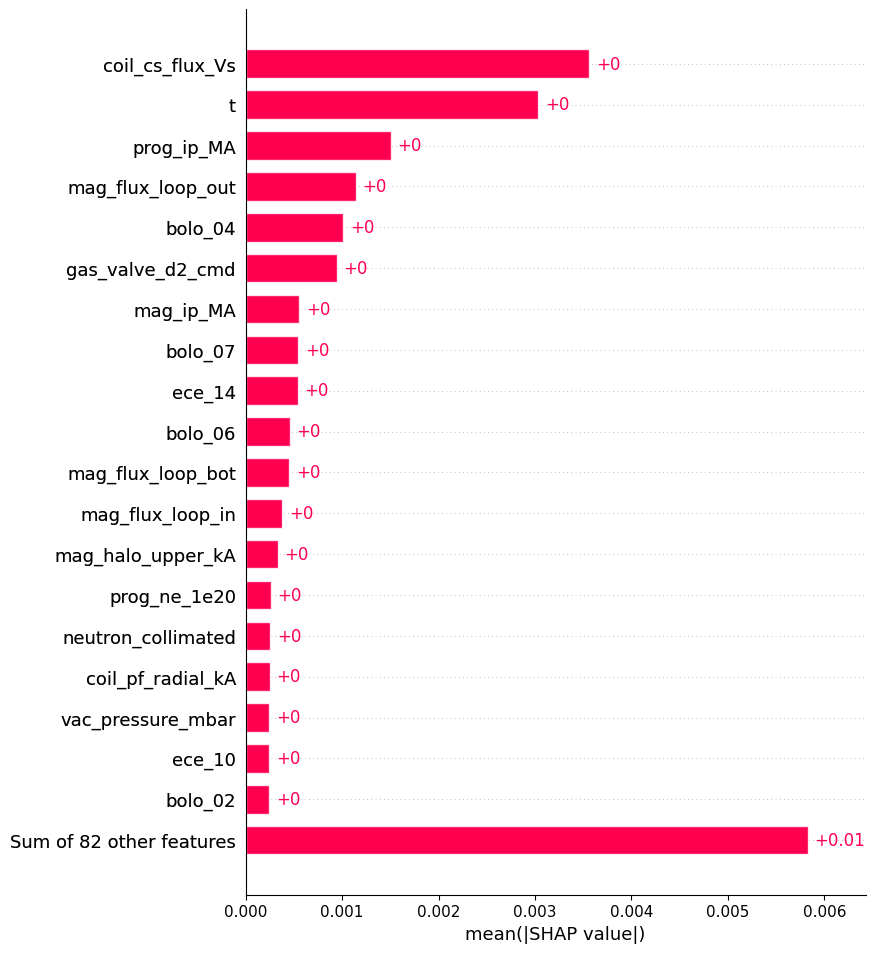

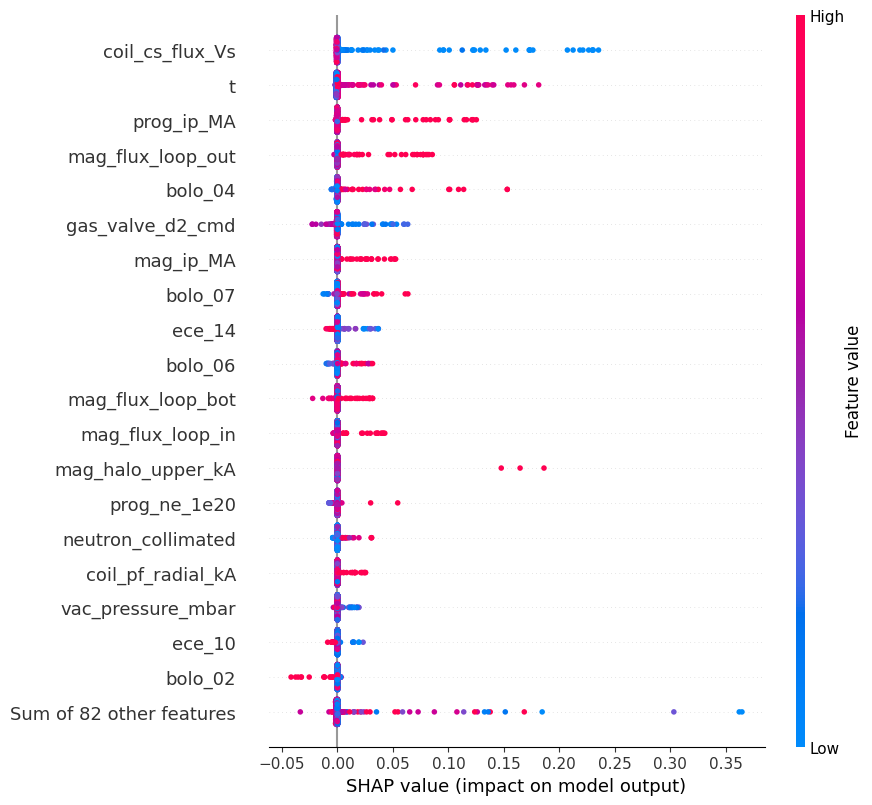

Максимальная оценка на выбранной подвыборке: 0.9947903156280518


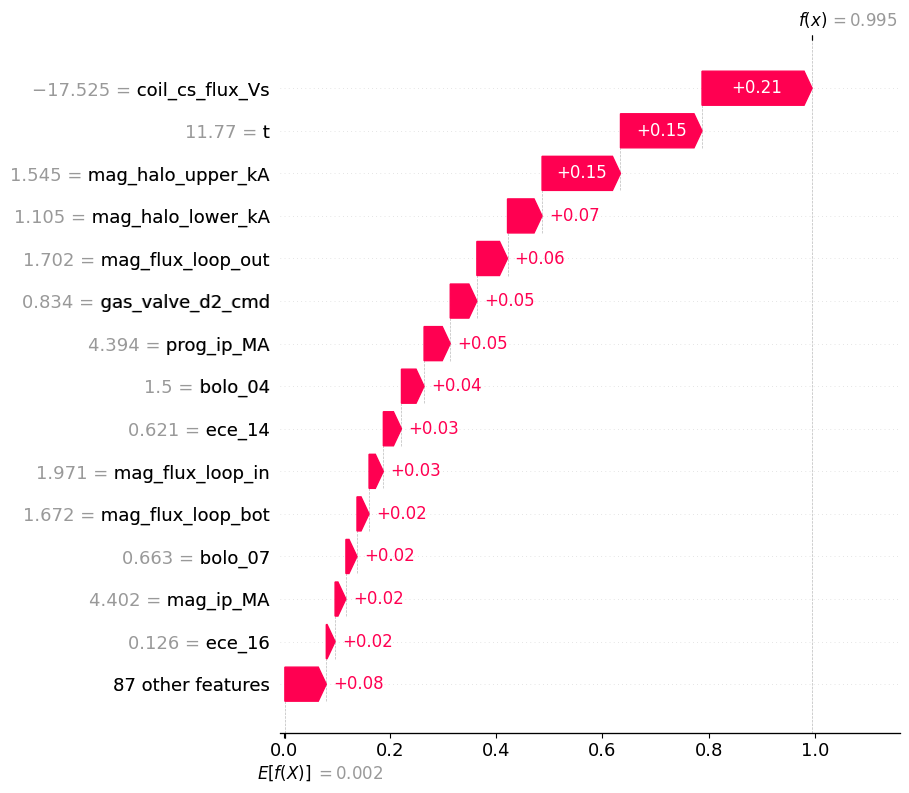

In [9]:

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Воспроизводимый выбор уже обученного на train классификатора.
# В текущей v2 таблице лучший вариант по Caught — Physics.
variant = str(results_df.iloc[0]["variant"])

model_shap = fitted_models[variant]
columns = feature_columns_used[variant]

# Проверочные данные не использовались при обучении этого экземпляра модели.
X_valid_shap = feature_sets[variant].loc[
    valid_mask, columns
].copy()

X_train_shap = feature_sets[variant].loc[
    train_mask, columns
].copy()

# Ограничиваем вычислительную нагрузку.
rng = np.random.default_rng(42)

if len(X_valid_shap) > 1500:
    chosen = rng.choice(
        len(X_valid_shap), size=1500, replace=False
    )
    X_explain = X_valid_shap.iloc[chosen].copy()
else:
    X_explain = X_valid_shap.copy()

background_size = min(100, len(X_train_shap))
background = X_train_shap.sample(
    n=background_size, random_state=42
)

print("Вариант:", variant)
print("Проверочных строк для SHAP:", len(X_explain))
print("Признаков:", len(columns))

# Для XGBoost считаем вклады в вероятность положительного класса.
# Если версия SHAP не поддерживает такой режим,
# используем стандартный TreeExplainer и его шкалу вывода модели.
try:
    explainer = shap.TreeExplainer(
        model_shap,
        data=background,
        feature_perturbation="interventional",
        model_output="probability",
    )
    shap_values = explainer(X_explain)

    shap_scale = "probability"

except Exception as exc:
    print("Режим probability недоступен:", str(exc)[:250])
    print("Используется стандартная шкала TreeExplainer.")

    explainer = shap.TreeExplainer(model_shap)
    shap_values = explainer(X_explain)

    shap_scale = "model output"

# Глобальная важность: среднее абсолютное значение SHAP.
values = np.asarray(shap_values.values)

if values.ndim != 2:
    raise ValueError(
        f"Неожиданная форма SHAP values: {values.shape}. "
        "Проверь версию SHAP и формат результата классификатора."
    )

shap_importance = pd.DataFrame({
    "feature": columns,
    "mean_abs_shap": np.abs(values).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False)

print("Шкала SHAP:", shap_scale)
display(shap_importance.head(25))

# 1. Глобальное ранжирование признаков.
shap.plots.bar(shap_values, max_display=20)

# 2. Направление и разброс влияния признаков по проверочным точкам.
shap.plots.beeswarm(shap_values, max_display=20)

# 3. Локальное объяснение точки с максимальным предсказанным риском
# среди строк, выбранных для объяснения.
p_explain = model_shap.predict_proba(X_explain)[:, 1]
local_idx = int(np.argmax(p_explain))

print(
    "Максимальная оценка на выбранной подвыборке:",
    float(p_explain[local_idx])
)

shap.plots.waterfall(
    shap_values[local_idx],
    max_display=15,
)
